# Softplus extension of the finite ring-attractor analysis

## Goal

Test how replacing the threshold-linear response function with
softplus changes:

1. Existence of bump fixed points
2. Local stability
3. Dependence of marginal tuning on JE and JI

## Current preliminary findings

- ReLU-tuned JE and JI collapse to a homogeneous fixed point state under the
  beta=2 softplus nonlinearity,instead of generating stable bump solution.
- Joint JE&JI parameter scan reveals a finite region containing stable bump
  candidates.
- Solving the fixed-point equations together with lambda_psi = 0
  gives a preliminary joint marginal-stability curve JE*(JI).

## Possible next steps

- Need to repeat for other N and several beta values.
- Need to compare velocity integration, zero-input drift, and noise
  sensitivity. Other possible property discoveries like limit cycles?

In [670]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
%pip install scipy

from scipy.optimize import root
from scipy.special import expit

import ra_utilities as util #Still ReLu


importlib.reload(util)

Note: you may need to restart the kernel to use updated packages.


<module 'ra_utilities' from '/Users/tinaguo/Desktop/Research/tina_neurocamp/ra_utilities.py'>

In [671]:
import scipy
import sys
import os

print(scipy.__version__)
print(sys.executable)
print(os.getpid())

1.18.0
/Users/tinaguo/miniforge3/envs/neuro/bin/python
14770


In [672]:
# Test 
print(util.preferred_headings(8))

[0.         0.78539816 1.57079633 2.35619449 3.14159265 3.92699082
 4.71238898 5.49778714]


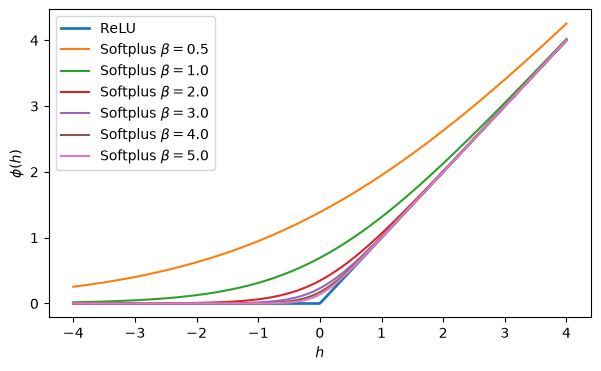

In [673]:
def relu(h):
    return np.maximum(h, 0.0)


def relu_prime(h):
    """Derivative of relu."""
    return (np.asarray(h) > 0.0).astype(float)


def softplus(h, beta=1.0):
    """Smooth approximation to ReLU."""
    h = np.asarray(h)
    return np.logaddexp(0.0, beta * h) / beta


def softplus_prime(h, beta=1.0):
    """Derivative of softplus."""
    return expit(beta * np.asarray(h))
#def sigmoid？

# Plot to show the comparison between softplus and ReLU
x = np.linspace(-4, 4, 500)

plt.figure(figsize=(7, 4))
plt.plot(x, relu(x), label="ReLU", lw=2)

for beta in [0.5, 1.0, 2.0, 3.0, 4.0, 5.0]:
    plt.plot(
        x,
        softplus(x, beta=beta),
        label=fr"Softplus $\beta={beta}$"
    )
# beta value 1.0 or 2.0 would provide better approximation
plt.xlabel(r"$h$")
plt.ylabel(r"$\phi(h)$")
plt.legend()
plt.show()

In [674]:
# Experiment on N and Beta Value

N = 6
beta = 1.0

EXPERIMENT_NAME = f"Softplus_N{N}_beta{beta:g}"

from pathlib import Path

PROJECT_DIR = Path.cwd()
SAVE_DIR = PROJECT_DIR / "experiments_softplus" / EXPERIMENT_NAME

SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("Running:", EXPERIMENT_NAME)
print("Saving to:", SAVE_DIR)

Running: Softplus_N6_beta1
Saving to: /Users/tinaguo/Desktop/Research/tina_neurocamp/experiments_softplus/Softplus_N6_beta1


In [675]:
# Comparison : ReLU results from article:
#N = 16
Nact = 6# Keep 3/4 ratio for now
# Concept of active neurons only applies to ReLU 

theta = util.preferred_headings(N)

cff = 1.0
tau = 0.1
#beta = 5.0

psi_preferred = theta[0]
psi_midpoint = 0.5 * (theta[0] + theta[1])

JE_relu = util.optimal_JE(N, Nact)
JI_relu = util.find_JI_for_amplitude(
    N,
    JE_relu,
    cff=cff,
    target_amplitude=0.2,
)

print("ReLU JE* =", JE_relu)
print("ReLU JI  =", JI_relu)

ReLU JE* = 2.0
ReLU JI  = -9.005682373046874


In [676]:
def rate_and_gain_projections(
    H0, a, psi, theta, phi, dphi
):
    """Compute the R and Q quantities of the reduced system.These are parameters to 
    simplify the matrix equation and fixed point calculation later on"""

    delta = theta - psi
    cos_delta = np.cos(delta)
    sin_delta = np.sin(delta)

    # h_k = H0 + a cos(theta_k - psi)
    h = H0 + a * cos_delta

    # Firing rate and local nonlinear gain
    r = phi(h)
    gain = dphi(h)

    # Rate projections
    R0 = np.mean(r)
    Rc = np.mean(r * cos_delta)
    Rs = np.mean(r * sin_delta)

    # Gain-weighted moments/projections
    Q0 = np.mean(gain)
    Q1 = np.mean(gain * cos_delta)
    Q2 = np.mean(gain * cos_delta**2)
    Qs = np.mean(gain * sin_delta**2)

    return {
        "h": h,
        "r": r,
        "gain": gain,
        "R0": R0,
        "Rc": Rc,
        "Rs": Rs,
        "Q0": Q0,
        "Q1": Q1,
        "Q2": Q2,
        "Qs": Qs,
    }

In [677]:
#A test run: Assign softplus under phi definition,assign random H0 and a)
phi = lambda h: softplus(h, beta=beta)
dphi = lambda h: softplus_prime(h, beta=beta)
# Define R and Q params to simplify Equations and Jacobian computation later.
q = rate_and_gain_projections(
    H0=-0.5,
    a=1.0,
    psi=psi_preferred,
    theta=theta,
    phi=phi,
    dphi=dphi,
)

for name in ["R0", "Rc", "Rs", "Q0", "Q1", "Q2", "Qs"]:
    print(name, q[name])

print("Q0 - (Q2 + Qs) =", q["Q0"] - q["Q2"] - q["Qs"])
#check Q0 - (Q2 + Qs)=0; Rs = 0(approx): 

R0 0.5313846663865326
Rc 0.19209153320651282
Rs 5.551115123125783e-17
Q0 0.39046128295803345
Q1 0.11184873100425057
Q2 0.19822592761553479
Qs 0.19223535534249872
Q0 - (Q2 + Qs) = -5.551115123125783e-17


Given (JI,JE,phi)：

0= -H0+ JI* R0+ cff

0= −a+ JE* Rc
	​


In [678]:
def fixed_point_residual(
    x, JI, JE, cff, psi, theta, phi, dphi
):
    H0, a = x

    q = rate_and_gain_projections(
        H0, a, psi, theta, phi, dphi
    )

    F0 = -H0 + JI * q["R0"] + cff
    Fa = -a + JE * q["Rc"]
    
    return np.array([F0, Fa])

In [679]:
# Gain initial guess??? Still use ReLU params for initial softplus computation
def extract_reduced_coordinates(h, theta):
    """Extract H0, a, psi from a network input profile h."""
    h = np.asarray(h)
#Fourier computation
    H0 = np.mean(h)
    H1 = np.mean(h * np.exp(-1j * theta))

    a = 2.0 * np.abs(H1)
    psi = (-np.angle(H1)) % (2.0 * np.pi)

    return H0, a, psi

phi = lambda h: softplus(h, beta=beta)
dphi = lambda h: softplus_prime(h, beta=beta)

h_final = util.simulate_bump(
    N=N,
    JE=JE_relu,#Use RelU 
    JI=JI_relu,
    cff=cff,
    vin=0.0,
    tau=tau,
    t_max=10.0,
    dt=0.01,
    psi0=psi_preferred,
    phi=phi,
    return_trajectory=False,
    animate=False,JE_noise=None, JI_noise=None, method="RK45"
)

#simulate_bump(N, JE, JI, cff=1.0, vin=0.0, tau=0.1, t_max=3.0, dt=0.01,
#                    psi0=0.0, h0=None, phi=threshold_linear,
#                    return_trajectory=True, animate=False,
#                    JE_noise=None, JI_noise=None, method="RK45")

H0_guess, a_guess,psi = extract_reduced_coordinates(
     h_final, theta)
#In this case psi shouldn't be a valid orientation 
print("initial guess:")
print("H0 guess =", H0_guess)
print("a guess =", a_guess)

#print(h_final)

# Relu parameter doesn't transfer directly to softplus, homogeneous fixed point result

initial guess:
H0 guess = -1.2566232626957523
a guess = 1.850371707708594e-16


In [680]:
#scipy.optimize.root solve
solution = root(fixed_point_residual,
    #x0=np.array([H0_guess, a_guess]),#starting from homgeneous branch
    x0=np.array([-1.0, 1.0]),#starting from other spot
    args=(
        JI_relu,
        JE_relu,
        cff,
        psi_preferred,
        theta,
        phi,
        dphi,
    ),
)

#Check test
print("success:", solution.success)# convergence success
print("message:", solution.message)#standard:"The solution converged"
print("residual:", solution.fun)# input results back to function, should be approx 0

H0_star, a_star= solution.x
q_check = rate_and_gain_projections(
    H0_star, a_star, psi_preferred,
    theta, phi, dphi
)

print("R0 =", q_check["R0"])
print("F0 =", -H0_star + JI_relu * q_check["R0"] + cff)


print("H0* =", H0_star)
print("a*  =", a_star)

# a star is approx zero, not a bump fixed point solution,homogeneuos fixed point

success: True
message: The solution converged.
residual: [ 4.48752147e-13 -3.58359475e-14]
R0 = 0.2505377042898578
F0 = 4.4875214655348827e-13
H0* = -1.2562629873072508
a*  = 4.6087006767331545e-14


In [681]:
# dhdt_final = util.network_rhs(
#     10.0,
#     h_final,
#     N,
#     JE_relu,
#     JI_relu,
#     cff,
#     0.0,          # vin
#     tau,
#     phi,
#     None,         # JE_noise
#     None          # JI_noise
# )

# print(dhdt_final)


In [682]:
# Calculate eigenvalues of the Jacobian
def reduced_eigenvalues(
    H0, a, psi, JI, JE, theta, phi, dphi, tau=1.0
):
    q = rate_and_gain_projections(
        H0, a, psi, theta, phi, dphi
    )

    Q0 = q["Q0"]
    Q1 = q["Q1"]
    Q2 = q["Q2"]
    Qs = q["Qs"]

    A = np.array([
        [-1.0 + JI * Q0, JI * Q1],
        [JE * Q1, -1.0 + JE * Q2],
    ])

    lambda_pm_dimensionless = np.linalg.eigvals(A)
    lambda_psi_dimensionless = -1.0 + JE * Qs

    return {
        "A": A,
        "lambda_pm": lambda_pm_dimensionless / tau,
        "lambda_psi": lambda_psi_dimensionless / tau,
        "quantities": q,
    }# Note:return a dictionary, use key to extract
# Use calculated eigenvalues from the dictionary(name:stability)
stability = reduced_eigenvalues(
    H0=H0_star,
    a=a_star,
    psi=psi_preferred,
    JI=JI_relu,
    JE=JE_relu,
    theta=theta,
    phi=phi,
    dphi=dphi,
    tau=tau,
)

print("A =")
print(stability["A"])

print("lambda_pm =", stability["lambda_pm"])
print("lambda_psi =", stability["lambda_psi"])

A =
[[-2.99582014e+00 -3.59731075e-14]
 [ 7.98897985e-15 -7.78382131e-01]]
lambda_pm = [-29.95820135+0.j  -7.78382131+0.j]
lambda_psi = -7.783821311149662


In [683]:
# #Check if reduced eigenvalues is the same as the elements from full jacobian eigenvalue sets
# def full_network_jacobian(
#     h_star, N, JE, JI, tau, dphi
# ):
#     W = util.symmetric_weights(N, JE, JI)
#     gain = dphi(h_star)

#     J = (
#         -np.eye(N)
#         + W * gain[None, :] / N#gain[None,:]--shape=(1, N)
#     ) / tau

#     return J

# q_star = stability["quantities"]
# h_star = q_star["h"]

# J_full = full_network_jacobian(
#     h_star=h_star,
#     N=N,
#     JE=JE_relu,
#     JI=JI_relu,
#     tau=tau,
#     dphi=dphi,
# )

# eig_full = np.linalg.eigvals(J_full)
# eig_full = eig_full[np.argsort(eig_full.real)[::-1]]# sort from max to min

# print("largest full-network eigenvalues:")
# print(eig_full[:])

# print("H0_star =", H0_star)
# print("a_star  =", a_star)

# q = stability["quantities"]
# #Printing these values out also comfirmed that we found homogeneous fixed points(h min=h max)
# print("h range =", q["h"].min(), q["h"].max())
# print("r range =", q["r"].min(), q["r"].max())

# print("R0 =", q["R0"])
# print("Rc =", q["Rc"])
# print("Rs =", q["Rs"])

# print("Q0 =", q["Q0"])
# print("Q1 =", q["Q1"])
# print("Q2 =", q["Q2"])
# print("Qs =", q["Qs"])

In [684]:
#This shows using JE JI value from ReLU result only found  homogeneous fixed points instead of a bump fixed point
#Using the analysis framework, we now solve for JE and JI value in other nonlinear function cases, need to rewrite functions to calculate JE
#along with selected JI values

In [685]:
def rate_and_gain_projections(
    H0, a, psi, theta, phi, dphi
):
    """Compute the R and Q quantities of the reduced system.These are parameters to 
    simplify the matrix equation and fixed point calculation later on"""

    delta = theta - psi
    cos_delta = np.cos(delta)
    sin_delta = np.sin(delta)

    # h_k = H0 + a cos(theta_k - psi)
    h = H0 + a * cos_delta

    # Firing rate and local nonlinear gain
    r = phi(h)
    gain = dphi(h)

    # Rate projections
    R0 = np.mean(r)
    Rc = np.mean(r * cos_delta)
    Rs = np.mean(r * sin_delta)

    # Gain-weighted moments/projections
    Q0 = np.mean(gain)
    Q1 = np.mean(gain * cos_delta)
    Q2 = np.mean(gain * cos_delta**2)
    Qs = np.mean(gain * sin_delta**2)

    return {
        "h": h,
        "r": r,
        "gain": gain,
        "R0": R0,
        "Rc": Rc,
        "Rs": Rs,
        "Q0": Q0,
        "Q1": Q1,
        "Q2": Q2,
        "Qs": Qs,
    }

In [686]:
# #JE_values calculated using projection equations

# JI_magnitude = abs(JI_relu)

# JI_values = -np.linspace(
#     0.05 * JI_magnitude,   #Weak inhibition
#     1.5 * JI_magnitude,    # Stronger inhibition
#     16,
# )

# print("JI range:", JI_values[0], JI_values[-1])

In [687]:
phi = lambda h: softplus(h, beta=beta)
dphi = lambda h: softplus_prime(h, beta=beta)
def fixed_point_new(
    x, JI, cff, psi, theta, phi, dphi
):
    H0, a, JE = x

    q = rate_and_gain_projections(
        H0, a, psi, theta, phi, dphi
    )

    F0 = -H0 + JI * q["R0"] + cff
    Fa = -a + JE * q["Rc"]
    FE = -1 + JE * q["Qs"]
    
    return np.array([F0, Fa,FE])


In [688]:
# First calculate JE from a set JI value, Use root-fingding method to get H0,a,JE value that
#satisfies fixed point requirement
JI_test=JI_relu

solution = root(fixed_point_new,
    #x0=np.array([H0_guess, a_guess]),#starting from homgeneous branch
    x0=np.array([-2.0, 2.0, 4.0]),#starting from other spot
    args=(
        JI_test,
        cff,
        psi_preferred,
        theta,
        phi,
        dphi,
    ),
)

#Check test
print("success:", solution.success)# convergence success
print("message:", solution.message)#standard:"The solution converged"
print("residual:", solution.fun)# input results back to function, should be approx 0

H0_ini, a_ini, JE_ini= solution.x
q_check = rate_and_gain_projections(
    H0_ini, a_ini, psi_preferred,
    theta, phi, dphi
)

print("R0 =", q_check["R0"])
print("F0 =", -H0_ini + JI_test * q_check["R0"] + cff)
print("Fa =",-a_ini + JE_ini * q_check["Rc"])
print("FE=",-1 + JE_ini * q_check["Qs"])

print("H0* =", H0_ini)
print("a*  =", a_ini)
print("JE*=",JE_ini)
print("JI=",JI_test)
# a star is approx zero, not a bump fixed point solution,homogeneuos fixed point

success: False
message: The number of calls to function has reached maxfev = 800.
residual: [ 2.38348710e-08 -2.12994333e-07  7.35343701e-08]
R0 = 0.2509695871431589
F0 = 2.3834870965799837e-08
Fa = -2.129943331152795e-07
FE= 7.353437014856468e-08
H0* = -1.2601524109408686
a*  = 0.173315884424729
JE*= 9.037174456642587
JI= -9.005682373046874


In [689]:
# # pass the solved JE value back to bump simulation and see the validity of solution
# t,h_final = util.simulate_bump(
#     N=N,
#     JE=JE_ini,
#     JI=JI_test,
#     cff=cff,
#     vin=0,
#     tau=tau,
#     t_max=10.0,
#     dt=0.01,
#     psi0=psi_preferred,
#     phi=phi,
#     return_trajectory=True,
#     animate=True,JE_noise=None, JI_noise=None, method="RK45"
# )

# #simulate_bump(N, JE, JI, cff=1.0, vin=0.0, tau=0.1, t_max=3.0, dt=0.01,
# #                    psi0=0.0, h0=None, phi=threshold_linear,
# #                    return_trajectory=True, animate=False,
# #                    JE_noise=None, JI_noise=None, method="RK45")

# H0_guess, a_guess,psi = extract_reduced_coordinates(
#      h_final, theta)
# #In this case psi shouldn't be a valid orientation 
# print("initial guess:")
# print("H0 guess =", H0_guess)
# print("a guess =", a_guess)


In [690]:
JI_magnitude=abs(JI_test)
JI_values = -np.linspace(0.5*JI_magnitude,2*JI_magnitude,16)

def find_target_JE(JI_test,H0_ini,a_ini):
    solution = root(fixed_point_new,
    x0=np.array([H0_ini, a_ini, JE_ini]),
    args=(
        JI_test,
        cff,
        psi_preferred,
        theta,
        phi,
        dphi,
    ))
    H0_star, a_star, JE_star= solution.x
    residual = np.linalg.norm(solution.fun)

    if not (
        np.all(np.isfinite(solution.x))
        and np.isfinite(residual)
        and JE_star > 0
    ):
        return np.nan, np.nan, np.nan

    return JE_star,a_star,H0_star


JE_values=[]
a_values=[]
H0_values=[]
for JI in JI_values:
    JE_star,a_star,H0_star=find_target_JE(JI,H0_ini,a_ini)
    JE_values.append(JE_star)
    a_values.append(a_star)
    H0_values.append(H0_star)
JE_values = np.array(JE_values)
a_values=np.array(a_values)
H0_values=np.array(H0_values)



print("JI values:", JI_values)
print("JE values:", JE_values)
print("a values:", a_values)
print("H0 values:", H0_values)



JI values: [ -4.50284119  -5.40340942  -6.30397766  -7.2045459   -8.10511414
  -9.00568237  -9.90625061 -10.80681885 -11.70738708 -12.60795532
 -13.50852356 -14.4090918  -15.30966003 -16.21022827 -17.11079651
 -18.01136475]
JE values: [ 6.2229589   6.81602813  7.38892918  7.94470749  8.49362013  9.03039784
  9.55330102 10.06600685 10.57322714 11.08058335 11.57108182 12.06493886
 12.54864334 13.03174753 13.52033705 13.97843761]
a values: [ 0.10823197 -0.11834303 -0.09600082 -0.00372797  0.09296345  0.11790115
  0.09930888  0.06196305 -0.05854478 -0.12713773 -0.10199349 -0.14192634
 -0.14876383 -0.17456393 -0.22815834 -0.19532481]
H0 values: [-0.747912   -0.87952574 -0.99172793 -1.08935501 -1.17824454 -1.25806405
 -1.32955412 -1.39480058 -1.45576339 -1.51428227 -1.56644983 -1.61759366
 -1.66473426 -1.7102692  -1.75554605 -1.7933638 ]


In [691]:
def diagnose_root(JI, x0):

    sol = root(
        fixed_point_new,
        x0=np.array(x0, dtype=float),
        args=(
            JI,
            cff,
            psi_preferred,
            theta,
            phi,
            dphi
        ),
        method="hybr",
        options={"maxfev": 5000}
    )

    H0, a, JE = sol.x

    return {
        "JI": JI,
        "success": sol.success,
        "H0": H0,
        "a": a,
        "JE": JE,
        "F0": sol.fun[0],
        "Fa": sol.fun[1],
        "FE": sol.fun[2],
        "residual": np.linalg.norm(sol.fun),
        "nfev": sol.nfev
    }


# Use the previously obtained candidate as initial guess
x0 = [H0_ini, a_ini, JE_ini]

results = []

for JI in JI_values:
    result = diagnose_root(JI, x0)
    results.append(result)

import pandas as pd

df = pd.DataFrame(results)

display(df)

,JI,success,H0,a,JE,F0,Fa,FE,residual,nfev
0,-4.502841,False,-0.747075,0.058063,6.221000,1.654188e-11,-8.042230e-10,6.258150e-11,8.068238e-10,5002
1,-5.403409,False,-0.878382,-0.058650,6.813150,3.936051e-11,9.372285e-10,6.950995e-11,9.406265e-10,5002
2,-6.303978,False,-0.991033,-0.056291,7.387054,2.664013e-11,8.048311e-10,6.384049e-11,8.077985e-10,5002
3,-7.204546,True,-1.089355,-0.003728,7.944707,-1.303602e-11,-6.431054e-15,1.992850e-12,1.318746e-11,15
4,-8.105114,False,-1.177573,0.057289,8.491559,2.095724e-11,-9.009117e-10,6.716117e-11,9.036547e-10,5002
5,-9.005682,False,-1.256773,0.062750,9.026203,3.604095e-11,-1.402877e-09,1.005183e-10,1.406935e-09,5002
6,-9.906251,False,-1.328718,0.059904,9.550429,1.732836e-11,-1.087449e-09,8.252377e-11,1.090714e-09,5002
7,-10.806819,True,-1.394801,0.061963,10.066007,-1.521666e-09,-1.265666e-09,-1.810302e-10,1.987498e-09,15
8,-11.707387,False,-1.455743,-0.057263,10.573148,8.664625e-12,8.119824e-10,5.130518e-11,8.136478e-10,1101
9,-12.607955,False,-1.512637,-0.067812,11.074039,7.902567e-11,1.805635e-09,1.914562e-10,1.817475e-09,5002


In [692]:
def preferred_headings(N):
    """Evenly spaced preferred headings theta_j for a ring of N neurons.

    Args:
        N: number of neurons (computational units) in the ring.

    Returns:
        Array of shape (N,) of preferred headings in [0, 2*pi).
    """
    return np.arange(N) * 2 * np.pi / N

def init_bump(N, psi0, width=None, amplitude=1.0):
    """Initialize a cosine-shaped bump of activity centered at psi0.

    Args:
        N: number of neurons.
        psi0: initial bump orientation (rad).
        width: unused placeholder kept for interface symmetry with the
            paper's (a, w, psi) bump parametrization; the single-ring model
            here uses a raw cosine bump instead.
        amplitude: peak activity of the initial bump.

    Returns:
        Array of shape (N,) giving initial input activity h_0.
    """
    theta = preferred_headings(N)
    return amplitude * np.cos(theta - psi0)

for i in range(len(JI_values)):

    N = len(theta)
    JI_fixed = JI_values[i]
    JE_fixed = JE_values[i]

    psi0 = psi_preferred
    H0_start = H0_values[i]

    a_initial_values = [0.01, 0.1, 0.5, 1.0, 2.0]
    a_initial_guesses = [
        -2.0, -1.0, -0.5, -0.1,
        0.1,  0.5,  1.0,  2.0
    ]


    for a_init in a_initial_values:

        # Initialize bump with a chosen amplitude
        h0 = H0_start + init_bump(
            N, psi0, amplitude=a_init
        )

        # Simulate the SAME network
        t, h = util.simulate_bump(
            N=N,
            JE=JE_fixed,
            JI=JI_fixed,
            cff=cff,
            vin=0.0,
            tau=tau,
            t_max=5000* tau,
            dt=tau,
            h0=h0,
            phi=phi,          # Use your sigmoid!
            animate=False,
            method="BDF"
        )

        h_final = h[-1]

    #simulate_bump(N, JE, JI, cff=1.0, vin=0.0, tau=0.1, t_max=3.0, dt=0.01,
    #                    psi0=0.0, h0=None, phi=threshold_linear,
    #                    return_trajectory=True, animate=False,
    #                    JE_noise=None, JI_noise=None, method="RK45")

        H0_now, a_now,psi = extract_reduced_coordinates(
            h_final, theta)
        print(  f"i = {i:.4f}  -->  "
                f"a_init = {a_init:.4f}  -->  "
                f"a_final = {a_now:.6f}, "
                f"H0_final = {H0_now:.6f}, "
                f"psi_final = {psi:.6f}"
            )

i = 0.0000  -->  a_init = 0.0100  -->  a_final = 0.071700, H0_final = -0.747253, psi_final = 0.000000
i = 0.0000  -->  a_init = 0.1000  -->  a_final = 0.108238, H0_final = -0.747912, psi_final = 6.283185
i = 0.0000  -->  a_init = 0.5000  -->  a_final = 0.108842, H0_final = -0.747925, psi_final = 6.283185
i = 0.0000  -->  a_init = 1.0000  -->  a_final = 0.108754, H0_final = -0.747923, psi_final = 6.283185
i = 0.0000  -->  a_init = 2.0000  -->  a_final = 0.108988, H0_final = -0.747929, psi_final = 6.283185
i = 1.0000  -->  a_init = 0.0100  -->  a_final = 0.098978, H0_final = -0.879070, psi_final = 0.000000
i = 1.0000  -->  a_init = 0.1000  -->  a_final = 0.118678, H0_final = -0.879535, psi_final = 6.283185
i = 1.0000  -->  a_init = 0.5000  -->  a_final = 0.118572, H0_final = -0.879532, psi_final = 6.283185
i = 1.0000  -->  a_init = 1.0000  -->  a_final = 0.118517, H0_final = -0.879530, psi_final = 6.283185
i = 1.0000  -->  a_init = 2.0000  -->  a_final = 0.118375, H0_final = -0.879527, p

In [693]:
#Residual precision: np.linalg.norm(solution.fun) > 1e-8; for solution 12,14,15; doesn't pass? Loosen precision?

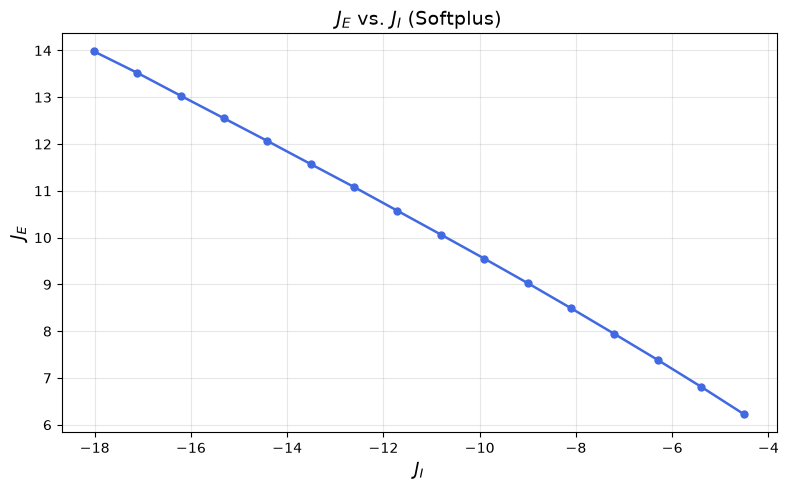

In [694]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(
    JI_values,
    JE_values,
    'o-',
    color='royalblue',
    linewidth=1.8,
    markersize=5
)

plt.xlabel(r'$J_I$', fontsize=13)
plt.ylabel(r'$J_E$', fontsize=13)
plt.title(r'$J_E$ vs. $J_I$ (Softplus)', fontsize=14)

plt.grid(True, alpha=0.3)
plt.tight_layout()

# plt.savefig(
#     SAVE_DIR / "JE_vs_JI.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

In [695]:
# np.savez(
#     SAVE_DIR / "coupling_scan.npz",
#     JI_values=JI_values,
#     JE_values=JE_values,
#     a_values=a_values,
#     H0_values=H0_values,
#     N=N,
#     beta=beta
# )

In [696]:
# for JI, JE in zip(JI_values, JE_values):

#     if not np.isfinite(JE):
#         continue

#     print(f"Simulating JI={JI:.3f}, JE={JE:.3f}")

#     t, h = util.simulate_bump(
#         N=N,
#         JE=JE,
#         JI=JI,
#         cff=cff,
#         vin=1.0,
#         tau=tau,
#         t_max=10.0,
#         dt=0.01,
#         psi0=psi_preferred,
#         phi=phi,
#         return_trajectory=True,
#         animate=True,
#         JE_noise=None,
#         JI_noise=None,
#         method="RK45"
#     )
#     h_final = h[-1]

#     H0_final, a_final, psi_final = (
#         extract_reduced_coordinates(h_final, theta)
#     )

#     print(f"JI = {JI:.3f}, JE = {JE:.3f}")
#     print(f"Final amplitude = {a_final:.6f}")
#     print(f"Final orientation = {psi_final:.6f}")
#     print("-" * 40)